In [1]:
import xarray as xr
import numpy as np
import dask
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import pathlib
import os

import global3d_track as g3d

In [2]:
# data
tobac_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/tbc_frozen_1e4/tropics')
track_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/dcc_frozen_1e4/tropics')

# save
saveloc = '/work/bb1153/b382635/plots/model_paper/grl_submission/figures/track_filtering/'
savedir = pathlib.Path(saveloc)
os.makedirs(savedir, exist_ok=1)

### collect record keeping

In [3]:
def collect_link_maps(link_maps, var, new_name):
    flag = 0
    for col in link_maps.columns:
        if 'secondary' in col:
            flag = 1
    if flag:
        link_maps = link_maps[[var,f'{var}_linked']].merge(link_maps[[f'{var}_secondary',f'{var}_linked_secondary']], left_on=f'{var}_linked', right_on=f'{var}_secondary', how='left').fillna(0)
        link_maps = link_maps.drop(columns=[f'{var}_linked',f'{var}_secondary']).rename(columns={var:new_name,f'{var}_linked_secondary':f'{new_name}_linked'})
    else:
        link_maps = link_maps.rename(columns={var:new_name,f'{var}_linked':f'{new_name}_linked'})
    return link_maps

def apply_linking(df, link_maps, var='dcc'):
    shift_val = link_maps[var].where(link_maps[var]>0).min() - 1
    df[var] = (df[var] + shift_val).where(df[var] > 0, 0)
    return df.merge(link_maps, left_on=var, right_on=var, how='left')

def load_records(day):
    # load track records for the day
    updrafts = pd.read_hdf(list(track_dir.glob('%s/*updraft_tracks.h5' %day))[0], 'table').rename(columns={'tracks':'updraft'})
    clouds = pd.read_hdf(list(track_dir.glob('%s/*frozen_tracks.h5' %day))[0], 'table').rename(columns={'tracks':'frozen'})
    # load overall system maps
    system_umaps = pd.read_hdf(list(track_dir.glob('%s/*system_label_maps.h5' %day))[0], 'table') # maps: updraft -> anvil
    system_amaps = pd.read_hdf(list(track_dir.glob('%s/*system_extra_maps.h5' %day))[0], 'table').rename(columns={'frozen_new':'dcc'}) # maps: anvil -> DCC
    system_maps = system_umaps.merge(system_amaps, left_on='frozen', right_on='frozen', how='left').fillna(0) # maps: updraft ->  anvil -> dcc
    # merge variable records with overall tracking results
    updrafts = updrafts.merge(system_maps[['updraft','dcc']], left_on='updraft', right_on='updraft', how='left').fillna(0)
    clouds = clouds.merge(system_maps[['frozen','dcc']], left_on='frozen', right_on='frozen', how='left').fillna(0)
    # load linking
    link_maps = pd.read_hdf(list(track_dir.glob('%s/*linked_system_maps.h5' %day))[0], 'table')
    updraft_maps = pd.read_hdf(list(track_dir.glob('%s/*linked_u_tracks_maps.h5' %day))[0], 'table')
    link_maps = collect_link_maps(link_maps, 'system', 'dcc')
    updraft_maps = collect_link_maps(updraft_maps, 'u_tracks', 'updraft')
    # link the updrafts in time
    updrafts = apply_linking(updrafts, updraft_maps, var='updraft')    
    # link the overall results in time
    updrafts = apply_linking(updrafts, link_maps, 'dcc')
    clouds = apply_linking(clouds, link_maps, 'dcc')
    # return
    updrafts = updrafts.rename(columns={'dcc':'dcc_daily','dcc_linked':'dcc','updraft':'updraft_daily','updraft_linked':'updraft'})
    clouds = clouds.rename(columns={'dcc':'dcc_daily','dcc_linked':'dcc'})
    return {'w':updrafts, 'cld':clouds}

def make_one_record(days):
    updrafts = None
    clouds = None
    for d in days:
        di = load_records(d)
        updrafts = pd.concat((updrafts, di['w']))
        clouds = pd.concat((clouds, di['cld']))
    dcc_times = pd.concat((updrafts[['time','dcc','updraft']], clouds[['time','dcc',]])).fillna(0)
    return updrafts, clouds, dcc_times

updrafts, clouds, dcc_times = make_one_record(('20210701','20210702','20210703','20210704'))

print(dcc_times.dcc.nunique(), 'DCCs tracked')

10206 DCCs tracked


### filter track quality

#### DEVELOP

In [4]:
# plot details

c = 'grey'
lparams = dict(ls=':', c='r')


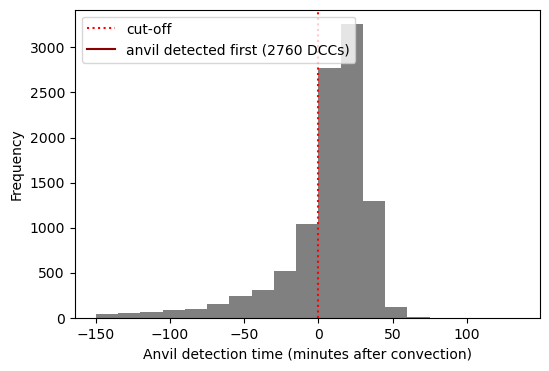

In [5]:
# 2 - anvil cannot preceed the convection

# find time of first detections
first_updraft = updrafts.groupby('dcc').time.min()
first_anvil = clouds.groupby('dcc').time.min()
inital_detections = pd.concat([first_updraft, first_anvil], axis=1, keys=['updraft', 'anvil'])

# how much time before the first anvil detection was the updraft?
t_before_anvil = pd.to_timedelta(inital_detections.anvil - inital_detections.updraft)
t_before_anvil = t_before_anvil.dt.total_seconds() / 60 # to minutes

# results
anvil_first = (t_before_anvil < 0).sum()
anvil_second = (t_before_anvil >= 0).sum()

bins = np.arange(-150, 150, 15)
fig, ax = plt.subplots(figsize=(6,4))
t_before_anvil.plot.hist(ax=ax, bins=bins, fc=c, label='')
ax.axvline(0, label='cut-off', **lparams)
# ax.plot([],[],c='darkgreen', label='convection first (%s DCCs)' %anvil_second)
ax.plot([],[],c='darkred', label='anvil detected first (%s DCCs)' %anvil_first)
ax.legend(loc='upper left')

ax.set(xlabel='Anvil detection time (minutes after convection)', title='')

fig.savefig(savedir / 'filter_anvils_that_precede_convection.jpg', bbox_inches='tight')

In [6]:
# 3 - the inital core centroid was below the freezing level

# get the updraft centroids at the inital time t
initial_updrafts = updrafts.where(updrafts.time_cell == pd.Timedelta(0)).dropna()
initial_zcentre = initial_updrafts.groupby('dcc')['height'].max() # take max model level (higher is close to the surface) where there were multiple

# load ICON heights in km
import intake
import easygems.healpix as egh
cat = intake.open_catalog("https://data.nextgems-h2020.eu/catalog.yaml")
ds = cat.ICON.ngc4008a(time="PT15M", zoom=9).to_dask().pipe(egh.attach_coords)['zg']
def cells_of_domain(ds):
    lon_min, lon_max, lat_min, lat_max = (277, 317, -15, 15)
    extent_mask = (ds["lon"] > lon_min) & (ds["lon"] < lon_max) & (ds["lat"] > lat_min) & (ds["lat"] < lat_max)
    return np.where(extent_mask)[0]
amazon_cells = cells_of_domain(ds)
amazon_ds = ds.sel(cell=amazon_cells)
zg_vals = amazon_ds.mean('cell') / 1000 # m to km


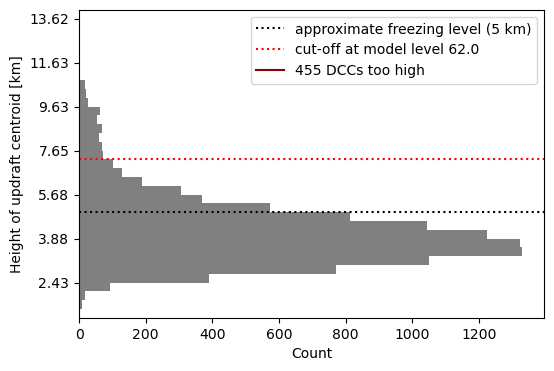

In [7]:
# results
mlevel = 62
kmlevel = 7.25
estimated_mlevel = (np.abs((zg_vals-kmlevel))).idxmin().item()
ntoo_high = initial_zcentre.where(initial_zcentre <= mlevel).dropna().index.size

fig, ax = plt.subplots(figsize=(6,4))

# hist
bins = zg_vals.level_full.values
ax.hist(initial_zcentre.values, bins=bins, fc=c, orientation='horizontal')
ax.set_yticks(bins[::5])
ax.set_yticklabels(zg_vals.sel(level_full=bins).values.round(2)[::5])
ax.set(ylabel='Height of updraft centroid [km]', ylim=(45,80), xlabel='Count')
ax.invert_yaxis()

# cut-offs
ax.axhline((np.abs((zg_vals-5))).idxmin(), c='k', ls=':', label='approximate freezing level (5 km)')
ax.axhline(estimated_mlevel, label='cut-off at model level %s' %estimated_mlevel, **lparams)
ax.plot([],[], c='darkred', label='%s DCCs too high' %ntoo_high)
ax.legend()

fig.savefig(savedir / 'filter_updrafts_above_freezing.jpg', bbox_inches='tight')

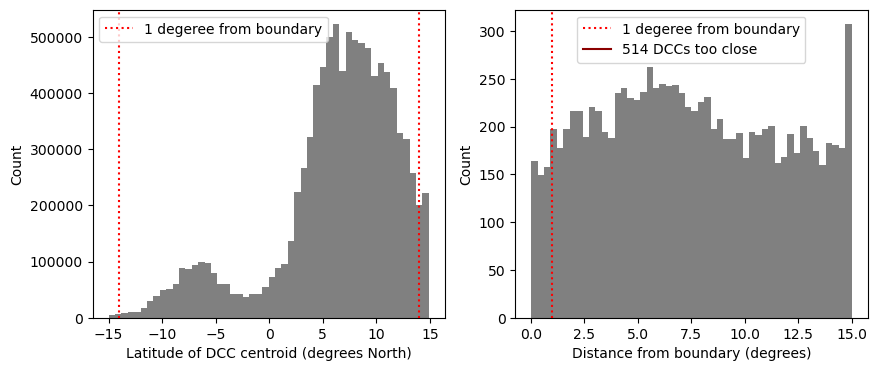

In [8]:
# 4 results intersect with the domain boundary

# count those with 1 deg
boundary_lat = 15
min_dist = 1 # degrees
closest_dist = clouds.groupby('dcc')['latitude'].apply(lambda x: boundary_lat - np.min(np.abs(x))) # get distance at closest points
count_too_close = (closest_dist <= min_dist).sum()

# results

fig, axs = plt.subplots(1,2, figsize=(10,4))
ax = axs[0]
ax.hist(clouds.latitude, bins=50, fc=c)
ax.set(xlabel='Latitude of DCC centroid (degrees North)', ylabel='Count')
ax.axvline(15-min_dist, label='%s degeree from boundary' %min_dist, **lparams)
ax.axvline(-15+min_dist, **lparams)
ax.legend()

ax= axs[1]
ax.hist(closest_dist, bins=50, fc=c)
ax.set(xlabel='Distance from boundary (degrees)', ylabel='Count')
ax.axvline(min_dist, ls=':', c='r', label='%s degeree from boundary' %min_dist)
ax.plot([],[], c='darkred', label='%s DCCs too close' %count_too_close)
ax.legend()

fig.savefig(savedir / 'filter_dccs_at_domain_boundary.jpg', bbox_inches='tight')


#### APPLY

In [9]:
# 1 - lifetime < 1 hour

df = pd.DataFrame()
def func(d):
    return (d.max() - d.min()).total_seconds() / (60*60) + 0.25 # to hours
lifetimes = dcc_times.where(dcc_times.dcc>0)[['time','dcc']].groupby('dcc')['time'].apply(func)

too_short = (lifetimes < 1)
print(too_short.sum(), 'were too short')

212 were too short


In [10]:
# 2 - anvil cannot preceed the convection

first_updraft = updrafts.groupby('dcc').time.min()
first_anvil = clouds.groupby('dcc').time.min()
inital_detections = pd.concat([first_updraft, first_anvil], axis=1, keys=['updraft', 'anvil'])
t_before_anvil = pd.to_timedelta(inital_detections.anvil - inital_detections.updraft)
t_before_anvil = t_before_anvil.dt.total_seconds() / 60 # to minutes

anvil_first = (t_before_anvil < 0)
print(anvil_first.sum(), 'had anvils first')

2760 had anvils first


In [11]:
# 3 - core initiated below the freezing level

# model level threshold
minlevel = 62

# get the updraft centroids at the inital time t
initial_updrafts = updrafts.where(updrafts.time_cell == pd.Timedelta(0)).dropna()
initial_zcentre = initial_updrafts.groupby('dcc')['height'].max() # take max model level (higher is close to the surface) where there were multiple

# filter rule
too_high = (initial_zcentre <= 62)
print(too_high.sum(), 'initated above freezing')

455 initated above freezing


In [12]:
# 4 - results intersect with the domain boundary

boundary_lat = 15
min_dist = 1 # degree
closest_dist = clouds.groupby('dcc')['latitude'].apply(lambda x: boundary_lat - np.min(np.abs(x))) # get distance at closest points
too_close = (closest_dist <= min_dist)
print(too_close.sum(), 'were too close to the domain boundary')

514 were too close to the domain boundary


In [13]:
# 5 - were the cores all at once? or at different times in the dcc lifecycle?

def conv_offset(df):
    group_time = df.groupby('updraft')['time']
    return group_time.min().max() - group_time.max().min()

def duration_first_core(d):
    updraft_start_times = d[d.updraft>0].groupby('updraft').time.min()
    inital_updrafts = updraft_start_times.index[updraft_start_times==updraft_start_times.min()]
    return func(d[d.updraft.isin(inital_updrafts)].time)

# calculate the number of time steps between the first core ending and the last core starting
offsets = updrafts.groupby('dcc')[['updraft','time']].apply(conv_offset)
offset_mins = (pd.to_timedelta(offsets).dt.total_seconds() / 60)
df_working = offset_mins.to_frame('offset') # minutes

# calculate related properties
df_working['duration_first_core'] = updrafts.groupby('dcc')[['updraft','time']].apply(duration_first_core)
df_working['lifetime'] = dcc_times.where(dcc_times.dcc>0)[['time','dcc']].groupby('dcc')['time'].apply(func)

# apply rule: if the duration of the first core was less than 1/4 of total cloud lifetime, allow a delay between first and last of 1/8 of total cloud lifetime
short_first_core = df_working.duration_first_core < 0.25 * df_working.lifetime
df_working['allowed_delay'] = (0.125 * df_working.lifetime * 60) * short_first_core # 0 or proportional to lifecycle characteristics

# if the last core started after the fist one ended, call it invalid
complicated_core_timing = df_working.offset > df_working.allowed_delay
print(complicated_core_timing.sum(), 'had complicated core timing')

3156 had complicated core timing


In [14]:
# all filtering results
filtering = lifetimes.to_frame('lifetime-hours')
filtering['time_before_anvil-minutes'] = t_before_anvil
filtering['inital_height-level'] = initial_zcentre
filtering['boundary_distrance-degrees'] = closest_dist
filtering['time_between_cores-minutes'] = offset_mins

# collect decisions
decisions = too_short.to_frame('too_short')
decisions['anvil_first'] = anvil_first
decisions['too_high'] = too_high
decisions['too_close'] = too_close
decisions['complex_convection'] = complicated_core_timing

# overall
count_fails = decisions[['too_short','anvil_first','too_high','too_close']].sum(axis=1)
decisions['invalid'] = count_fails > 0
decisions['valid_but_complex_convection'] = np.logical_and(count_fails==0, decisions.complex_convection)
decisions['valid'] = np.logical_and(count_fails==0, ~decisions.complex_convection)

# collect
validity = pd.concat((filtering, decisions), axis=1)

# count
decisions.sum(axis=0)


too_short                        212
anvil_first                     2760
too_high                         455
too_close                        514
complex_convection              3156
invalid                         3407
valid_but_complex_convection    2198
valid                           4600
dtype: int64

In [15]:
print('total valid',2198+4600)

total valid 6798


#### DEVELOP ISOLATED DEFINITION

In [16]:
# 5 - were the cores all at once? or at different times in the dcc lifecycle?

def conv_offset(df):
    group_time = df.groupby('updraft')['time']
    return group_time.min().max() - group_time.max().min()

# calculate the number of time steps between the first core ending and the last core starting
offsets = updrafts.groupby('dcc')[['updraft','time']].apply(conv_offset)
ntsteps = pd.to_timedelta(offsets).dt.total_seconds() / 60 # minutes
core_timing = ntsteps.to_frame('offset')

# threshold, minimum allowed gap
GAP = 0 * 15 # minutes

# calculate some related statistics
def lifetime(d):
    return (d.max() - d.min()).total_seconds() / (60*60) + 0.25 # to hours
core_timing['lifetime'] = dcc_times.where(dcc_times.dcc>0)[['time','dcc']].groupby('dcc')['time'].apply(lifetime)
core_timing['ncores'] = updrafts[['updraft','dcc']].groupby('dcc')['updraft'].nunique()
core_timing['is_simple'] = core_timing.offset <= GAP
core_timing['conv_lifetime'] = updrafts.groupby('dcc')['time'].apply(lifetime)

def duration_first_core(d):
    updraft_start_times = d[d.updraft>0].groupby('updraft').time.min()
    inital_updrafts = updraft_start_times.index[updraft_start_times==updraft_start_times.min()]
    return lifetime(d[d.updraft.isin(inital_updrafts)].time)
core_timing['duration_first_core'] = updrafts.groupby('dcc')[['updraft','time']].apply(duration_first_core)
core_timing['prop_active'] = core_timing.conv_lifetime / core_timing.lifetime

# second simplicity test
# - if first core lasts < 25% total lifetime
short_first_core = core_timing.duration_first_core < 0.25 * core_timing.lifetime
# - there is an extra allowed delay of 12.5% of total lifetime
allowed_delay = 0.125 * core_timing.lifetime * 60 # minutes
# allowed_delay = 30 # minutes
# - otherwise, there is no allowed delay
new_test = core_timing.offset <= allowed_delay * short_first_core
core_timing['is_simple_plus'] = np.logical_or(core_timing.is_simple, new_test)

# assess valid cases only
core_timing['invalid'] = decisions.invalid
core_timing = core_timing[core_timing.invalid==False]

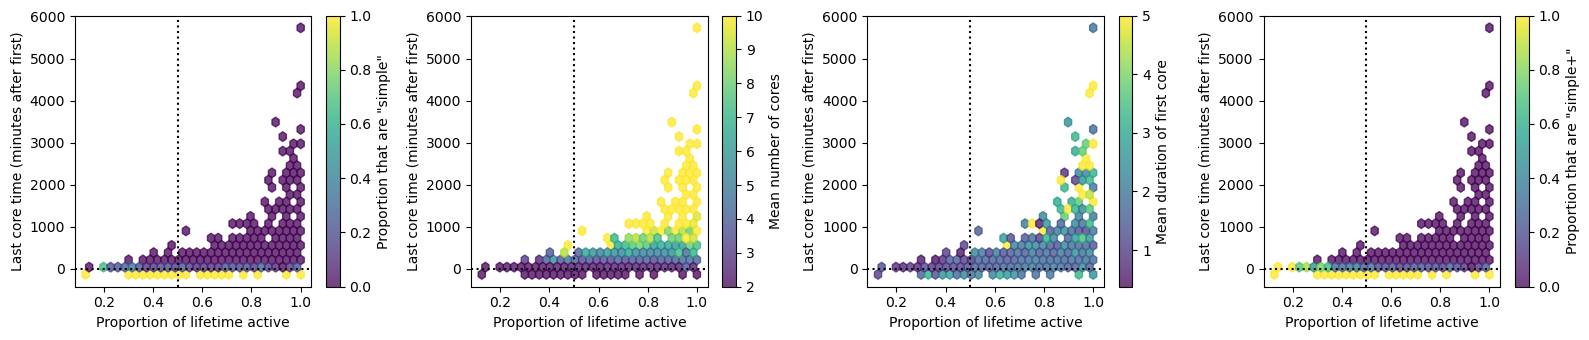

In [17]:
# what cases are we missing ?
multi_cores = core_timing[core_timing.ncores>1]

fig, axs = plt.subplots(1,4, figsize=(16, 3.5), layout='tight')
hparams = dict(gridsize=30, mincnt=1, alpha=0.75, reduce_C_function=np.mean)

ax = axs[0]
hb = ax.hexbin(multi_cores.prop_active, multi_cores.offset, C=multi_cores.is_simple, **hparams)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('Proportion that are "simple"')
ax.set(xlabel='Proportion of lifetime active', ylabel='Last core time (minutes after first)')

ax = axs[1]
ncores = multi_cores.ncores.where(multi_cores.ncores<10,10)
hb = ax.hexbin(multi_cores.prop_active, multi_cores.offset, C=ncores, **hparams)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('Mean number of cores')
ax.set(xlabel='Proportion of lifetime active', ylabel='Last core time (minutes after first)')

ax = axs[2]
duration = multi_cores.duration_first_core.where(multi_cores.duration_first_core<5,5)
hb = ax.hexbin(multi_cores.prop_active, multi_cores.offset, C=duration, **hparams)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('Mean duration of first core')
ax.set(xlabel='Proportion of lifetime active', ylabel='Last core time (minutes after first)')

# pretend new definition
ax = axs[3]
hb = ax.hexbin(multi_cores.prop_active, multi_cores.offset, C=multi_cores.is_simple_plus, **hparams)
cbar = plt.colorbar(hb, ax=ax)
cbar.set_label('Proportion that are "simple+"')
ax.set(xlabel='Proportion of lifetime active', ylabel='Last core time (minutes after first)')

for ax in axs:
    ax.axhline(GAP, ls=':', c='k')
    ax.axvline(0.5, ls=':', c='k')

fig.savefig(savedir / 'filter_by_simple_convection_QC.jpg', bbox_inches='tight')

In [18]:
core_timing[['is_simple','is_simple_plus']].sum()

is_simple         4463
is_simple_plus    4600
dtype: int64

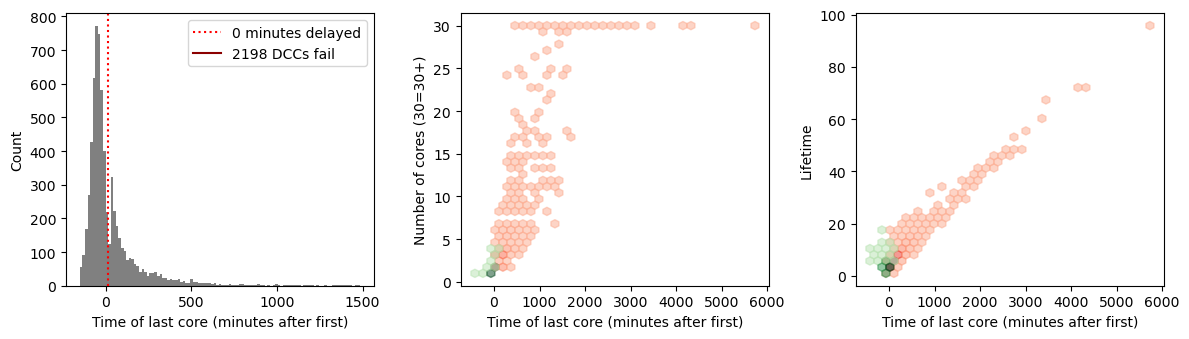

In [19]:
# results

is_okay = core_timing.is_simple_plus
m_true = is_okay
m_false = is_okay == False

def hexplot(ax, y):
    N = len(core_timing)
    extent = [core_timing.offset.min(), core_timing.offset.max(), y.min(), y.max()]
    cmap1 = mpl.colors.ListedColormap(plt.get_cmap('Reds')(np.linspace(.3,1,265)))
    cmap2 = mpl.colors.ListedColormap(plt.get_cmap('Greens')(np.linspace(.3,1,265)))
    params = dict(extent=extent, gridsize=35, mincnt=1, alpha=0.5)
    params1 = dict(C=np.ones(m_false.sum()) / N, reduce_C_function=np.sum, cmap=cmap1)
    params2 = dict(C=np.ones(m_true.sum()) / N, reduce_C_function=np.sum, cmap=cmap2)
    ax.hexbin(core_timing.offset[m_false], y[m_false], **params1, **params)
    ax.hexbin(core_timing.offset[m_true], y[m_true], **params2, **params)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5), layout='tight')

ax = axs[0]
bins = np.arange(-10*15, 100*15, 15)
ax.hist(core_timing.offset, bins=bins, fc='grey')
ax.set(xlabel='Time of last core (minutes after first)', title='', ylabel='Count')
ax.axvline(GAP+15, label="%s minutes delayed" %(GAP), **lparams)
ax.plot([],[],c='darkred',label='%s DCCs fail' %m_false.sum())
ax.legend()
 
ax = axs[1]
X = 30
ncores = core_timing.ncores.where(core_timing.ncores<X, X)
hexplot(ax, ncores)
ax.set(xlabel='Time of last core (minutes after first)', ylabel='Number of cores (%s=%s+)' %(X,X))

ax = axs[2]
hexplot(ax, core_timing.lifetime)
ax.set(xlabel='Time of last core (minutes after first)', ylabel='Lifetime')

fig.savefig(savedir / 'filter_by_simplicity_of_convection_QC.jpg', bbox_inches='tight')


### get track statistics

#### DERIVE

In [20]:
df = pd.DataFrame(index=validity.index)

In [21]:
# 1 - lifetimes
def lifetime(d):
    return (d.max() - d.min()).total_seconds() / (60*60) + 0.25 # to hours
df['lifetime'] = dcc_times[['time','dcc']].groupby('dcc')['time'].apply(lifetime)

In [22]:
# 2 - number of cores per DCC
df['ncores'] = updrafts[['updraft','dcc']].groupby('dcc')['updraft'].nunique()

In [23]:
# 3 - associate to key regions
di = {"global": (-180,180,-15,15),
      "amazon": (-83, -43, -15, 15),
      "congo": (1, 41, -15, 15),
      "warm_pool": (90, 160, -15, 15)
     }
regions = di.keys()
for r in di.keys():
    longitudes = (di[r][0], di[r][1])
    within = lambda x: np.logical_and(x>longitudes[0], x<longitudes[1]).any()
    df[r] = clouds.groupby('dcc')['longitude'].apply(within)

In [24]:
# 4 - time of initiation
df['initial_time'] = dcc_times.groupby('dcc')['time'].min().astype(str)
df["initial_time"] = pd.to_datetime(df["initial_time"])

# 5 - lifetime of convection
df['duration_convection'] = updrafts.groupby('dcc')['time'].apply(lifetime)

In [25]:
# 6 - inital latitude and longitude
def initial_data(d):
    return d.sort_values('time').iloc[0]
initial_data = updrafts.groupby('dcc')[['latitude','longitude','time']].apply(initial_data)
df['initial_lat'] = initial_data.latitude
df['initial_lon'] = initial_data.longitude

In [26]:
# X - add filtering results

df['valid_but_complex_convection'] = validity.valid_but_complex_convection
df['valid'] = validity.valid

In [27]:
df.head()

,lifetime,ncores,global,amazon,congo,warm_pool,initial_time,duration_convection,initial_lat,initial_lon,valid_but_complex_convection,valid
dcc,,,,,,,,,,,,
1.0,95.75,137,True,False,False,True,2021-07-01 00:15:00,95.75,-3.679068,144.774295,True,False
2.0,24.00,45,True,False,False,False,2021-07-04 00:00:00,24.00,3.062571,-3.032222,True,False
3.0,7.50,3,True,False,True,False,2021-07-02 00:00:00,5.50,8.600409,17.759948,True,False
4.0,11.00,7,True,False,False,True,2021-07-02 00:00:00,7.25,-7.386997,121.550132,True,False
5.0,5.50,2,True,False,False,True,2021-07-03 00:00:00,3.50,-4.048660,126.455654,True,False


#### RESULTS

In [28]:
good_df = df[np.logical_or(df.valid_but_complex_convection, df.valid)]

In [29]:
# maximum number of cores for one system:

for r in regions:
    count = good_df.where(np.logical_and(good_df.ncores>20, good_df.loc[:,r]==True)).ncores.max()
    print(r, int(count))

global 525
amazon 195
congo 525
warm_pool 148


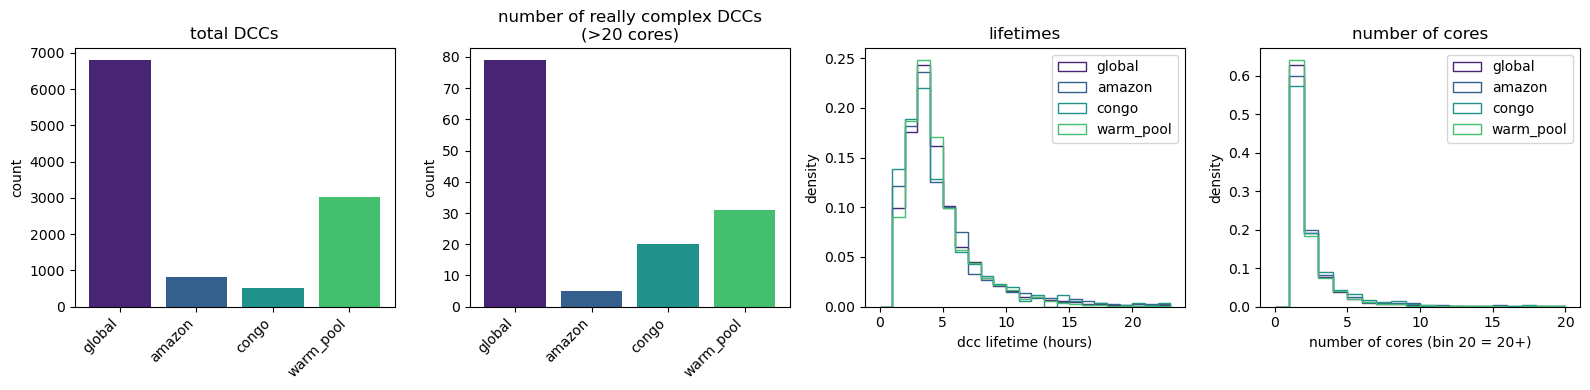

In [30]:
# a big bucket of results

plot_df = good_df

fig, axs = plt.subplots(1,4, figsize=(16,4), layout='tight')

cmap = plt.get_cmap('viridis')
params = dict(histtype='step', density=1)

ax = axs[2]
bins = np.arange(0, 24, 1)
for i, r in enumerate(regions):
    d = plot_df.where(plot_df.loc[:, r] == True).lifetime.dropna()
    _ = ax.hist(d, bins=bins, ec=cmap(i / 5 + .1), label=r, **params)
ax.set_xlabel('dcc lifetime (hours)')
ax.set_ylabel('density')
ax.legend()
ax.set_title('lifetimes')

ax = axs[3]
bins = np.arange(0, 21, 1)
for i, r in enumerate(regions):
    d = plot_df.where(plot_df.loc[:, r] == True).ncores.dropna()
    _ = ax.hist(d, bins=bins, ec=cmap(i / 5 + .1), label=r, **params)
ax.set_xlabel('number of cores (bin 20 = 20+)')
ax.set_ylabel('density')
ax.legend()
ax.set_title('number of cores')

ax = axs[0]
x = np.arange(len(regions))
total_by_region = plot_df[list(regions)].sum()
ax.bar(x, total_by_region.loc[list(regions)], color=[cmap(i / 5 + .1) for i in range(len(regions))])
ax.set_xticks(x)
ax.set_xticklabels(regions, rotation=45, ha='right')
ax.set_ylabel('count')
ax.set_title('total DCCs')

ax = axs[1]
complex_by_region = pd.Series({r: plot_df.loc[np.logical_and(plot_df.ncores > 20, df.loc[:, r] == True), r].sum() for r in regions })
ax.bar(x, complex_by_region.loc[list(regions)], color=[cmap(i / 5 + .1) for i in range(len(regions))])
ax.set_xticks(x)
ax.set_xticklabels(regions, rotation=45, ha='right')
ax.set_ylabel('count')
ax.set_title('number of really complex DCCs\n(>20 cores)')

fig.savefig(savedir / 'track_regional_summary_QC.jpg', bbox_inches='tight')


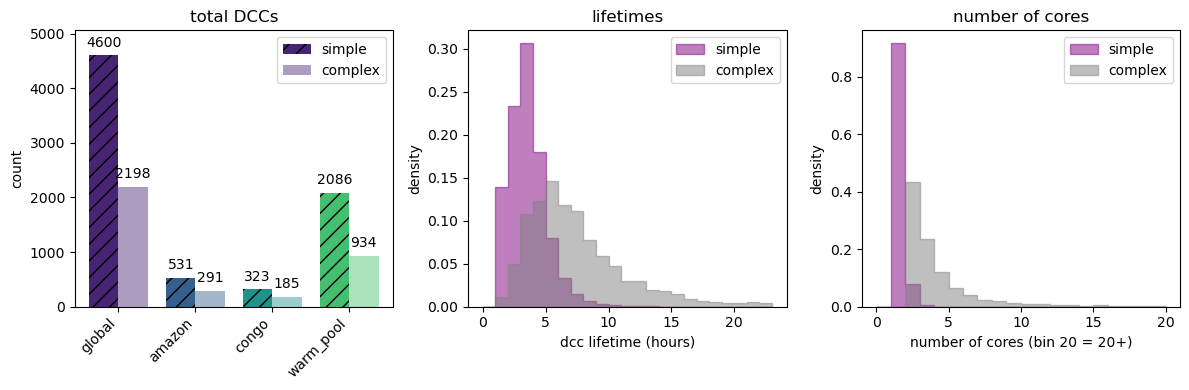

In [31]:
# compare simple DCCs to those that ain't

simple_df = df[df.valid]
complex_df = df[df.valid_but_complex_convection]

c1 = 'purple'
c2 = 'grey'
hparams = dict(histtype="stepfilled", density=True, alpha=.5)

fig, axs = plt.subplots(1,3, figsize=(12,4), layout="tight")

cmap = plt.get_cmap("viridis")
regions = list(regions)
x = np.arange(len(regions))
width = 0.38

# total dccs by region
ax = axs[0]
simple_total = simple_df[regions].sum()
complex_total = complex_df[regions].sum()

def label_bars(heights, rects):
    for height, rect in zip(heights, rects):
        ax.annotate(f'{height}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points vertical offset.
                    textcoords='offset points',
                    ha='center', va='bottom')

rects = ax.bar(x - width / 2, simple_total.loc[regions], width=width, hatch="//", color=[cmap(i / 5 + 0.1) for i in range(len(regions))], label="simple")
label_bars(simple_total.loc[regions], rects)
rects = ax.bar(x + width / 2, complex_total.loc[regions], width=width, color=[cmap(i / 5 + 0.1) for i in range(len(regions))], alpha=0.45, label="complex")
label_bars(complex_total.loc[regions], rects)
ax.set_xticks(x)
ax.set_xticklabels(regions, rotation=45, ha="right")
ax.set_ylabel("count")
ax.set_title("total DCCs")
ax.legend()
ax.set_ylim(None, np.max((complex_total.loc[regions], simple_total.loc[regions]))*1.1)

# global lifetime distributions only
ax = axs[1]
bins = np.arange(0, 24, 1)
ax.hist(simple_df.lifetime.dropna(), bins=bins, ec=c1, fc=c1, label="simple", **hparams)
ax.hist(complex_df.lifetime.dropna(), bins=bins, ec=c2, fc=c2, label="complex", **hparams)
ax.set_xlabel("dcc lifetime (hours)")
ax.set_ylabel("density")
ax.set_title("lifetimes")
ax.legend()

# global number of cores distributions only
ax = axs[2]
bins = np.arange(0, 21, 1)
ax.hist(simple_df.ncores.dropna(), bins=bins, ec=c1, fc=c1, label="simple", **hparams)
ax.hist(complex_df.ncores.dropna(), bins=bins, ec=c2, fc=c2, label="complex", **hparams)
ax.set_xlabel("number of cores (bin 20 = 20+)")
ax.set_ylabel("density")
ax.set_title("number of cores")
ax.legend()

fig.savefig(savedir / "track_summary_simple_vs_complex_QC.jpg", bbox_inches="tight")

#### SAVE

In [32]:
outpath = pathlib.Path(track_dir, 'track_stats')
outpath.mkdir(parents=1, exist_ok=1)

In [33]:
outpath

PosixPath('/work/bb1153/b382635/data/final_tracks/dcc_frozen_1e4/tropics/track_stats')

In [34]:
# validity.to_csv(outpath / 'dcc_validity.csv')

In [35]:
# df.to_csv(outpath / 'dcc_statistics.csv')